In [1]:
import pandas as pd
import joblib
import shap

# Saved model aur cheezein load karo
model = joblib.load('../models/churn_model.pkl')
feature_columns = joblib.load('../models/feature_columns.pkl')
best_threshold = joblib.load('../models/best_threshold.pkl')

# Cleaned data load karo
df = pd.read_csv('../data/processed/telco_cleaned.csv')

print("Model loaded:", type(model))
print("Number of features:", len(feature_columns))
print("Threshold:", best_threshold)

Model loaded: <class 'xgboost.sklearn.XGBClassifier'>
Number of features: 43
Threshold: 0.3


In [2]:
# Target aur features alag karo (Module 2 jaisa hi)
y = df['Churn Label'].map({'Yes': 1, 'No': 0})
X = df.drop(columns=['Churn Label', 'Churn Category', 'Churn Reason'])

# Categorical columns identify karo
categorical_cols = X.select_dtypes(include='object').columns.tolist()

# One-Hot Encoding (Module 2 jaisa hi)
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

# Train-test split (SAME random_state=42 use karo, taaki wahi test set mile jo Module 2 mein use hua tha)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

print("X_test shape:", X_test.shape)
print("Columns match saved feature_columns:", list(X_test.columns) == feature_columns)

X_test shape: (1409, 43)
Columns match saved feature_columns: True


In [3]:
# XGBoost ke liye TreeExplainer use karte hain (tree-based models ke liye fast aur accurate)
explainer = shap.TreeExplainer(model)

# SHAP values calculate karo test set ke liye
shap_values = explainer.shap_values(X_test)

print("SHAP values calculated!")
print("Shape:", shap_values.shape)

SHAP values calculated!
Shape: (1409, 43)


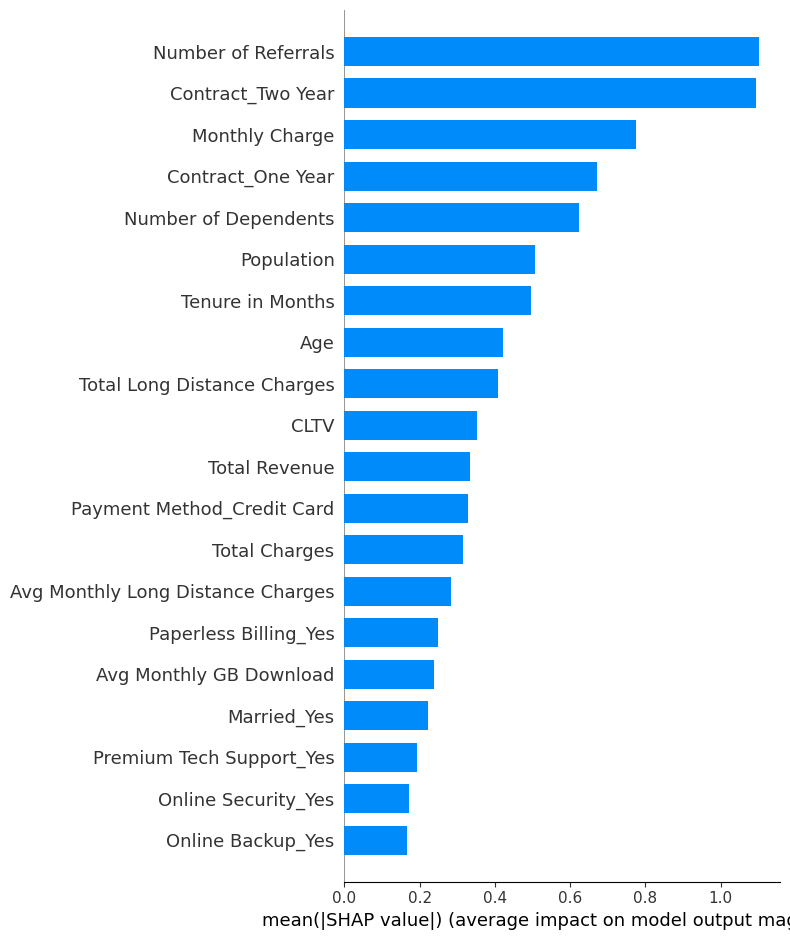

In [5]:
import matplotlib.pyplot as plt

shap.summary_plot(shap_values, X_test, plot_type='bar')

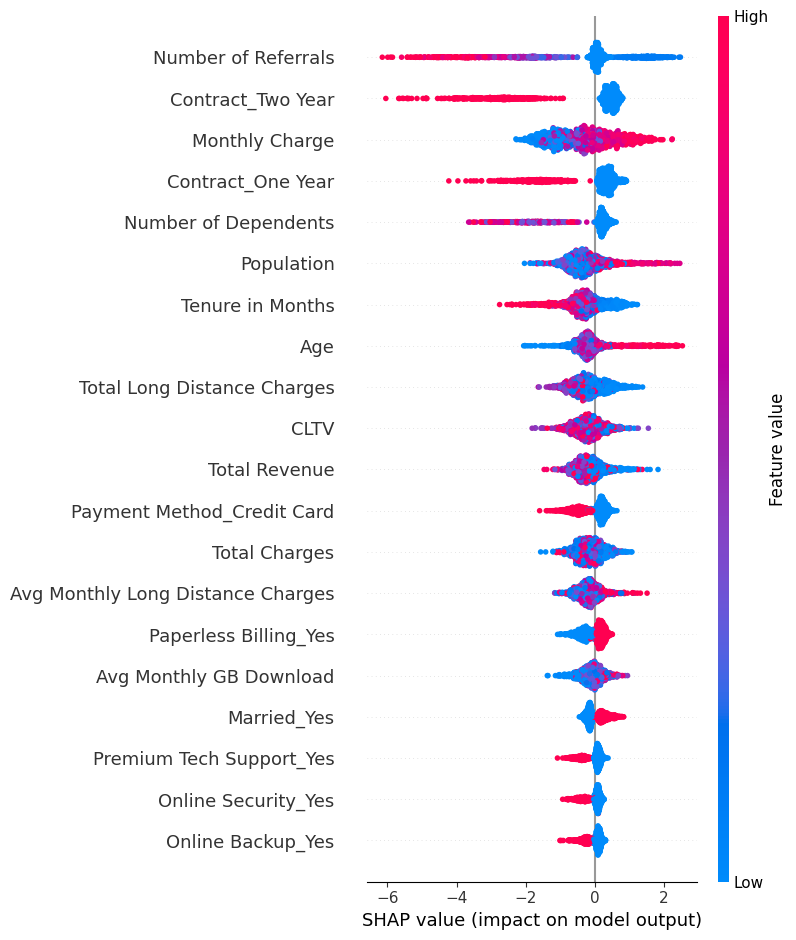

In [6]:
shap.summary_plot(shap_values, X_test)

Actual Churn: 0
Predicted Probability: 0.0057408246


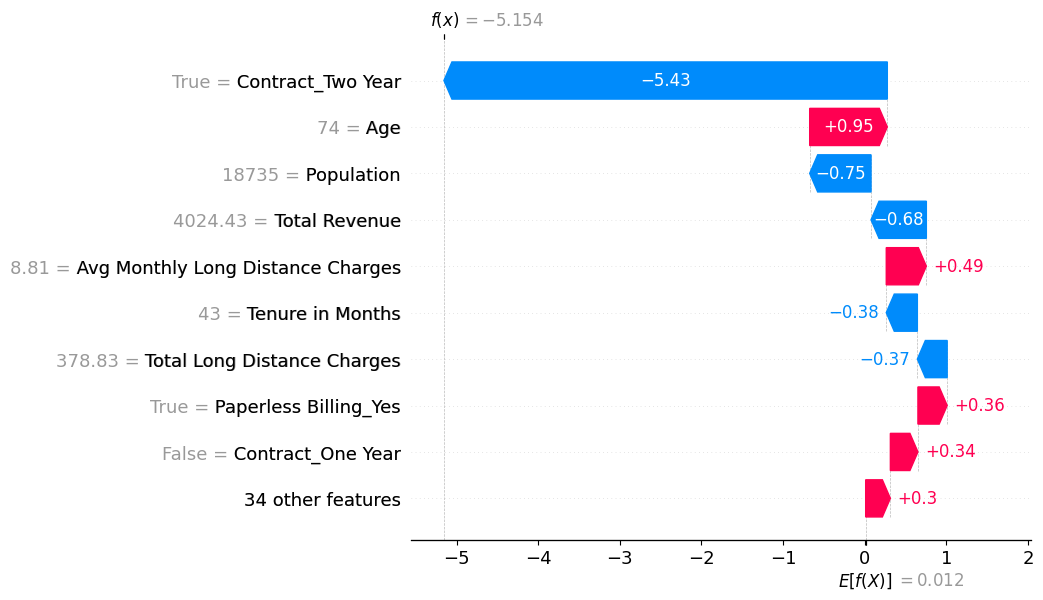

In [7]:
# Ek customer choose karo test set se (jo actually churn predict hua)
import numpy as np

customer_index = 0  # pehla customer test set ka

print("Actual Churn:", y_test.iloc[customer_index])
print("Predicted Probability:", model.predict_proba(X_test.iloc[[customer_index]])[:, 1][0])

# Waterfall plot - is customer ke liye SHAP explanation
shap.waterfall_plot(shap.Explanation(
    values=shap_values[customer_index], 
    base_values=explainer.expected_value, 
    data=X_test.iloc[customer_index],
    feature_names=X_test.columns.tolist()
))

Actual Churn: 1
Predicted Probability: 0.9946503


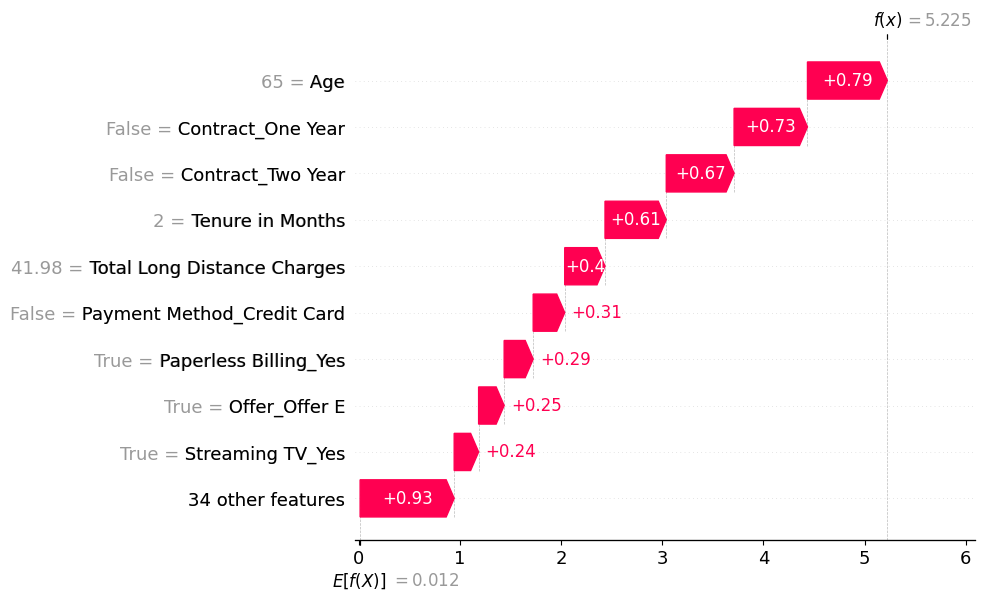

In [8]:
# Ek churned customer dhoondo test set mein
churned_indices = np.where(y_test.values == 1)[0]
customer_index_2 = churned_indices[0]  # pehla churned customer

print("Actual Churn:", y_test.iloc[customer_index_2])
print("Predicted Probability:", model.predict_proba(X_test.iloc[[customer_index_2]])[:, 1][0])

shap.waterfall_plot(shap.Explanation(
    values=shap_values[customer_index_2], 
    base_values=explainer.expected_value, 
    data=X_test.iloc[customer_index_2],
    feature_names=X_test.columns.tolist()
))

In [9]:
def get_top_shap_reasons(customer_index, top_n=5):
    """
    Given a customer's index in X_test, return their top N churn-driving factors
    (feature name, their value, and SHAP contribution)
    """
    shap_vals = shap_values[customer_index]
    feature_vals = X_test.iloc[customer_index]
    
    # Feature, value, aur SHAP contribution ko combine karo
    contributions = pd.DataFrame({
        'feature': X_test.columns,
        'value': feature_vals.values,
        'shap_value': shap_vals
    })
    
    # Sabse zyada positive impact wale (churn badhane wale) top N nikalo
    top_positive = contributions.sort_values('shap_value', ascending=False).head(top_n)
    
    return top_positive

# Test karo churned customer pe
print(get_top_shap_reasons(customer_index_2, top_n=5))

                        feature  value  shap_value
0                           Age     65    0.789707
38            Contract_One Year  False    0.725631
39            Contract_Two Year  False    0.670740
4              Tenure in Months      2    0.605729
11  Total Long Distance Charges  41.98    0.398458


In [10]:
import joblib

# SHAP values aur explainer save karo
joblib.dump(shap_values, '../models/shap_values.pkl')
joblib.dump(explainer, '../models/shap_explainer.pkl')

# X_test bhi save karo (SHAP values ke saath match karne ke liye zaroori hai)
X_test.to_csv('../data/processed/X_test.csv', index=False)
y_test.to_csv('../data/processed/y_test.csv', index=False)

print("SHAP values, explainer, aur test data saved successfully!")

SHAP values, explainer, aur test data saved successfully!
